In [1]:
import os
import numpy as np
import pandas as pd
from scipy.stats import percentileofscore
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
import spacy
import missingno as msno
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import seaborn as sns
from datetime import datetime

# Loading Data

In [2]:
# Directory where CSV files are located
path = '/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/StockTwits-from-2008-to-2022/data/finance.csv'

df = pd.read_csv(path)

del path

# EDA (short verification)

In [3]:

df["user_id"] = df["user_id"].astype(pd.CategoricalDtype(ordered=False))
df["day"] = df["day"].astype(pd.CategoricalDtype(ordered=True))
df['generated_sentiment_01'] = df['generated_sentiment'] == 'HAUSSE'
print(df.info())
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 10302146 entries, 0 to 10302145
Data columns (total 10 columns):
 #   Column                  Dtype   
---  ------                  -----   
 0   user_id                 category
 1   day                     category
 2   sentiment               str     
 3   ticker                  str     
 4   J+1                     bool    
 5   J+3                     bool    
 6   J+7                     bool    
 7   J+30                    bool    
 8   generated_sentiment     str     
 9   generated_sentiment_01  bool    
dtypes: bool(5), category(2), str(3)
memory usage: 346.9 MB
None


,user_id,day,sentiment,ticker,J+1,J+3,J+7,J+30,generated_sentiment,generated_sentiment_01
0,549,147,UNKNOWN,AAPL,True,True,True,False,HAUSSE,True
1,126,147,UNKNOWN,AAPL,True,True,True,False,BAISSE,False
2,785,148,UNKNOWN,AAPL,False,False,False,False,HAUSSE,True
3,549,148,UNKNOWN,AAPL,False,False,False,False,BAISSE,False
4,4589,149,UNKNOWN,AAPL,True,False,False,False,HAUSSE,True


In [4]:
print(df.isna().mean()*100)
df.describe(include='all')
# msno.matrix(df)
# plt.show()

user_id                   0.0
day                       0.0
sentiment                 0.0
ticker                    0.0
J+1                       0.0
J+3                       0.0
J+7                       0.0
J+30                      0.0
generated_sentiment       0.0
generated_sentiment_01    0.0
dtype: float64


,user_id,day,sentiment,ticker,J+1,J+3,J+7,J+30,generated_sentiment,generated_sentiment_01
count,10302146,10302146,10302146,10302146,10302146,10302146,10302146,10302146,10302146,10302146
unique,385131,5541,3,2,2,2,2,2,2,2
top,260062,5198,UNKNOWN,TSLA,False,True,True,True,HAUSSE,True
freq,30818,36702,6308301,5548219,5249568,5269319,5271807,5192045,5759898,5759898


# Data TSLA

Nous avons choisi de travailler sur les données relatives à l'action Tesla (TSLA). Ce choix a été motivé par le fait qu'elle bénéficie d'un fort intérêt de la part des investisseurs. Ainsi beaucoup de messages concernant ce titre ont été émis sur Stocktwits, qui puis est assez régulièrement. Ainsi l'action Tesla (TSLA) est une parfaite candidate pour l'entrainement de notre modèle de machine learning visant à prédire l'évolution de son cours à l'horizon de x jours. 

## Data TSLA (base)

Nos données au départ se présentent sous la forme d'un tableau "df_tsla" composé de 5548219 lignes correspondantes chacune à un message expédié par l'un des 252990 utilisateurs échangeant sur le sujet durant la période du 26/05/2008 au 30/12/2023. Sur cette période, on compte 4699 jours d'activité, autrement dit 4699 jours où au moins un message a été posté au sujet de Tesla sur Stocktwits. Pour chacun de ces messages, nous connaissons à l'horizon J+1, J+3, J+7 et J+30, si l'action Tesla avait augmenté ou baissé depuis le jour de publication. Le prix de l'action Tesla à une date donnée est déterminé au moment de la clôture marché. Les sentiments à la hausse ou la baisse de $\approx 46\%$ de ces messages ont été annotés à la main. Pour le reste de ces messages, nous avons choisi d'inférer leurs sentiments en utilisant le modèle RoBERTa que nous avions entrainé précédemment (cf partie Matthieu). Pour la suite bien que la précision de modèle RoBERTa n'est pas de $100\%$ (en l'occurrence $\approx 83\%$) on choisira comme vérité terrains ces sentiments prédits pour entrainer notre classifieur.

In [5]:
df_tsla = df[df['ticker'] == 'TSLA']

# Liste des horizons temporels à traiter
horizons_cols = ['J+1', 'J+3', 'J+7', 'J+30']
for h in horizons_cols:
    df_tsla[f'fiability_{h}'] = (df_tsla['generated_sentiment_01'] == df_tsla[h]).astype(int)

# Création de la colonne 'fiability' (1 si au moins un horizon est correct, 0 sinon)
fiability_cols = ['fiability_J+1', 'fiability_J+3', 'fiability_J+7', 'fiability_J+30']
df_tsla['fiability'] = df_tsla[fiability_cols].any(axis=1).astype(int)

# for h in horizons:
#     col_name = f'fiability_{h}'
#     df_tsla[col_name] = df_tsla.groupby('user_id')[col_name].transform('mean')

del horizons_cols, fiability_cols, h

df_tsla.describe(include='all')

,user_id,day,sentiment,ticker,J+1,J+3,J+7,J+30,generated_sentiment,generated_sentiment_01,fiability_J+1,fiability_J+3,fiability_J+7,fiability_J+30,fiability
count,5548219.0,5548219.0,5548219,5548219,5548219,5548219,5548219,5548219,5548219,5548219,5.548219e+06,5.548219e+06,5.548219e+06,5.548219e+06,5.548219e+06
unique,252990.0,4699.0,3,1,2,2,2,2,2,2,NaN,NaN,NaN,NaN,NaN
top,1824468.0,4648.0,UNKNOWN,TSLA,False,False,False,False,HAUSSE,True,NaN,NaN,NaN,NaN,NaN
freq,28928.0,23816.0,3001873,5548219,2910748,2810689,2867539,2888797,3026802,3026802,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.001515e-01,5.040729e-01,4.986388e-01,5.039006e-01,7.806912e-01
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000e-01,4.999835e-01,4.999982e-01,4.999848e-01,4.137783e-01
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


## Data TSLA sentiment fiability by day

Dans un premier nous nous sommes intéressés à la fiabilité à l'horizon J+1, J+3, J+7 et J+30 de l'ensemble de ces messages, en comparant leurs sentiments avec l'évolution réelle du cours de l'action. Les résultats sont médiocres, et cela, quelque fusse l'horizon choisi la fiabilité des sentiment sur l'ensemble des 5548219 messages ($\approx 50\%$) ne font pas mieux que le hasard d'une pièce de monnaie. Or ce résultat avait d'ores et déjà été décrit dans l'article de Xingji Li et al. "StockTwits: Comprehensive records of a financial social media platform from 2008 to 2022".

In [6]:
# Dictionnaire des agrégations par jour
agg_dict_day = {'fiability_J+1': 'mean',
                'fiability_J+3': 'mean',
                'fiability_J+7': 'mean',
                'fiability_J+30': 'mean',
                'ticker': 'count'  # Compte le nombre total de lignes (messages) par jour
                }

df_tesla_day = df_tsla.groupby('day').agg(agg_dict_day).rename(columns={'user_id': 'message_count'}).reset_index()

del agg_dict_day

In [7]:
df_tesla_day.describe(include='all')

,day,fiability_J+1,fiability_J+3,fiability_J+7,fiability_J+30,ticker
count,4699.0,4699.000000,4699.000000,4699.000000,4699.000000,4699.000000
unique,4699.0,NaN,NaN,NaN,NaN,NaN
top,909.0,NaN,NaN,NaN,NaN,NaN
freq,1.0,NaN,NaN,NaN,NaN,NaN
mean,NaN,0.503715,0.507148,0.509856,0.514842,1180.723345
std,NaN,0.163839,0.163725,0.163584,0.163207,1903.835456
min,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
25%,NaN,0.415885,0.418651,0.418861,0.424242,71.500000
50%,NaN,0.500000,0.502591,0.502703,0.508306,428.000000
75%,NaN,0.593407,0.596663,0.597886,0.600875,1459.500000


## Data TSLA users community

Aussi est-il possible que parmi ce bruit blanc que représentent les sentiments de ces 5548219 messages, un signal véritablement informatif puisse émerger ? Pour répondre à cette question, on choisit d'établir un filtrage important de nos données. Ce filtrage exhibe alors une communauté d'utilisateurs de Stocktwits dont fiabilité moyenne de leurs messages appartiennent au $60^{ème}$ quantiles et dont l'activité minimum sur le site est supérieure à 90 jours. Cela réduit alors la liste d'utilisateur de $252990$ à $56$. On les nommera experts de la communauté Tesla par la suite.

Ainsi parmi ces experts, on note une activité médiane de 139 jours pour une fiabilité médiane à l'horizon J+1 de $\approx 65\%$, J+3 de $\approx 67\%$, J+7 de $\approx 69\%$ et J+30 de $\approx 74\%$

Notons pour la suite que l'activité de notre communauté d'expert n'est pas constante dans le temps, on discerne 2 grandes périodes aux alentours du mois de MM de l'année AAAA. De plus lorsque l'on calcule pour l'ensemble de la communauté d'expert sa fiabilité moyenne glissante sur 90 jours, on observe que celle-ci n'est pas constante non plus. Nous verrons par la suite, que ces deux aspects jouerons un rôle déterminant lors de l'attribution des poids par notre classifieur à chacun des experts de cette communauté. 

In [8]:
# Dictionnaire des agrégations par utilisateur
agg_dict_user = {'day': 'nunique',                 # Nombre de jours distincts d'activité (= assiduité)
                 'fiability_J+1': 'mean',          # Taux moyen de réussite à J+1
                 'fiability_J+3': 'mean',          # Taux moyen de réussite à J+3
                 'fiability_J+7': 'mean',          # Taux moyen de réussite à J+7
                 'fiability_J+30': 'mean',         # Taux moyen de réussite à J+30
                 'fiability': 'mean'               # Taux moyen global de réussite
                 }

df_tsla_community = df_tsla.groupby('user_id').agg(agg_dict_user).rename(columns={'day': 'assiduity'}).reset_index()

del agg_dict_user

In [9]:
df_tsla_community.describe(include='all')

,user_id,assiduity,fiability_J+1,fiability_J+3,fiability_J+7,fiability_J+30,fiability
count,252990.0,252990.000000,252990.000000,252990.000000,252990.000000,252990.000000,252990.000000
unique,252990.0,NaN,NaN,NaN,NaN,NaN,NaN
top,1.0,NaN,NaN,NaN,NaN,NaN,NaN
freq,1.0,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,8.448765,0.500289,0.510408,0.499987,0.522022,0.786666
std,NaN,34.732214,0.391637,0.394188,0.396118,0.400393,0.328571
min,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,0.687500
50%,NaN,1.000000,0.500000,0.500000,0.500000,0.500000,1.000000
75%,NaN,5.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Data TSLA users top community

In [10]:
fiability_cols = ['fiability_J+1', 'fiability_J+3', 'fiability_J+7', 'fiability_J+30']

quantile = df_tsla_community[fiability_cols].quantile(0.6)
print(quantile)

assiduity_treshold = 90

# Filtrer les utilisateurs au-dessus ou égal à un quantile donné sur les 4 horizons en même temps
filter_top_community = ((df_tsla_community['fiability_J+1'] >= quantile['fiability_J+1']) & 
                        (df_tsla_community['fiability_J+3'] >= quantile['fiability_J+3']) & 
                        (df_tsla_community['fiability_J+7'] >= quantile['fiability_J+7']) & 
                        (df_tsla_community['fiability_J+30'] >= quantile['fiability_J+30']) & 
                        (df_tsla_community['assiduity'] >= assiduity_treshold)
                        )

# # Filtrer les utilisateurs au-dessus ou égal à un quantile donné sur l'horizons J+30
# filter_top_community = ((df_tsla_community['fiability_J+30'] >= quantile['fiability_J+30']) & 
#                         (df_tsla_community['assiduity'] >= assiduity_treshold)
#                         )

df_tsla_top_community = df_tsla_community[filter_top_community]

del fiability_cols, quantile, assiduity_treshold, filter_top_community

fiability_J+1     0.589286
fiability_J+3     0.612903
fiability_J+7     0.600000
fiability_J+30    0.666667
Name: 0.6, dtype: float64


In [11]:
df_tsla_top_community.describe(include='all')

,user_id,assiduity,fiability_J+1,fiability_J+3,fiability_J+7,fiability_J+30,fiability
count,56.0,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000
unique,56.0,NaN,NaN,NaN,NaN,NaN,NaN
top,260524.0,NaN,NaN,NaN,NaN,NaN,NaN
freq,1.0,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,175.089286,0.681259,0.695549,0.710720,0.762181,0.865472
std,NaN,117.335305,0.080007,0.068677,0.073674,0.076133,0.057003
min,NaN,91.000000,0.589474,0.615894,0.600398,0.668942,0.761092
25%,NaN,109.500000,0.618653,0.648289,0.656432,0.695833,0.822319
50%,NaN,139.000000,0.650500,0.672878,0.692177,0.744916,0.864127
75%,NaN,190.500000,0.727591,0.725126,0.745870,0.811189,0.910794


In [12]:
# Récupération de la liste des user_id experts
top_user_ids = df_tsla_top_community['user_id']
df_tsla_top_messages = df_tsla[df_tsla['user_id'].isin(top_user_ids)].copy()

# Vérification
print(f"Number of messages extracted : {len(df_tsla_top_messages)}")
print(f"Verfication of the number of users : {df_tsla_top_messages['user_id'].nunique()}")

Number of messages extracted : 49391
Verfication of the number of users : 56


In [13]:
df_tsla_top_messages.describe(include='all')

,user_id,day,sentiment,ticker,J+1,J+3,J+7,J+30,generated_sentiment,generated_sentiment_01,fiability_J+1,fiability_J+3,fiability_J+7,fiability_J+30,fiability
count,49391.0,49391.0,49391,49391,49391,49391,49391,49391,49391,49391,49391.000000,49391.00000,49391.000000,49391.000000,49391.000000
unique,56.0,1614.0,3,1,2,2,2,2,2,2,NaN,NaN,NaN,NaN,NaN
top,804663.0,5587.0,UNKNOWN,TSLA,False,False,False,False,BAISSE,False,NaN,NaN,NaN,NaN,NaN
freq,7644.0,508.0,38985,49391,37296,37295,38618,42688,37480,37480,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.690996,0.69786,0.709178,0.763277,0.869085
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.462087,0.45919,0.454146,0.425075,0.337310
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.00000,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.00000,0.000000,1.000000,1.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.00000,1.000000,1.000000,1.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.00000,1.000000,1.000000,1.000000


### Machine learning model to predict TSLA stock evolution

#### Statistic verification of TSLA top community's fiability (Test binomial)

Avant de construire notre classifieur, nous nous sommes intéressés à la significativité de nos données ainsi filtrées. En particulier à la significativité de la fiabilité de chacun de nos experts aux horizons J+1, J+3, J+7 et J+30. Pour cela, nous avons réalisé le test binomial unilatéral avec comme hypothèse nulle $H_0$ "Le taux de réussite réel de l'expert est égal à 50 % ($p = 0.5$)." et donc comme hypothèse alternative $H_1$ : Le taux de réussite de l'expert est strictement supérieur à 50 % ($p > 0.5$)". A l'issue des tests, la plus grande p-valeur est $\approx 9.6 \cdot 10^{-6}\ll 0.05$ calculée pour l'expert dont le user_id = 1716381. Ainsi, l'ensemble des 56 experts affichent une p-valeur très inférieure à $0.05$, ce qui rejette sans aucune ambiguïté l'hypothèse nulle $H_0$ selon laquelle leurs fiabilités pourraient être seulement le fruit du hasard. Notre communauté d'experts semble donc fiable statistiquement.

In [14]:
from scipy.stats import binomtest

In [21]:
def evaluate_expert(group):
    n_trials = len(group)
    n_successes = int(group['fiability_J+30'].sum())
    
    # Test binomial unilatéral afin de tester si l'expert fait significativement mieux que 0.5 (hasard)
    res = binomtest(n_successes, n_trials, p=0.5, alternative='greater')

    df_stats = pd.Series({'total_predictions': n_trials,
                          'successes': n_successes,
                          'success_rate': n_successes/n_trials,
                          'p_value': res.pvalue
                          })
    
    return df_stats

# Application du test binomial pour chaque expert
df_expert_stats = df_tsla_top_messages.groupby('user_id').apply(evaluate_expert).reset_index()
df_expert_stats = df_expert_stats.sort_values(by='p_value', ascending=False)

# Filtrer les experts dont la p-value est inférieure à 5%
alpha = 0.05
significant_experts = df_expert_stats[df_expert_stats['p_value'] < alpha]

print(f"\nNumber of expert with (p < {alpha}) : {len(significant_experts)} sur {len(df_expert_stats)}")
del alpha, significant_experts
df_expert_stats.describe(include='all')


Number of expert with (p < 0.05) : 56 sur 56


,user_id,total_predictions,successes,success_rate,p_value
count,56.0,56.000000,56.000000,56.000000,5.600000e+01
unique,56.0,NaN,NaN,NaN,NaN
top,260524.0,NaN,NaN,NaN,NaN
freq,1.0,NaN,NaN,NaN,NaN
mean,NaN,881.982143,673.196429,0.762181,1.834035e-07
std,NaN,1195.916590,916.643629,0.076133,1.289810e-06
min,NaN,151.000000,102.000000,0.668942,0.000000e+00
25%,NaN,269.250000,215.500000,0.695833,1.023359e-68
50%,NaN,508.000000,379.000000,0.744916,1.634933e-34
75%,NaN,888.000000,657.000000,0.811189,1.487805e-15


#### Preparation of the Data TSLA top community messages for our logistic regression model

In [16]:
from sklearn.model_selection import train_test_split

In [17]:
# Encodage des sentiment en (-1, +1) en vu de la régression logistique
df_tsla_top_messages['sentiment_encoded'] = (df_tsla_top_messages['generated_sentiment_01'].astype(int) * 2 - 1)

X = df_tsla_top_messages.pivot_table(index='day',
                                     columns='user_id',
                                     values='sentiment_encoded',
                                     aggfunc='mean'
                                     )

# 0 si un expert n'a pas émis d'avis un jour donné
X.fillna(0, inplace=True)

# Récupération de la variable à expliquer (y) pour l'horizon J+30 et alignement avec X
y_per_day = df_tsla_top_messages.groupby('day')['J+30'].first().astype(int)
X, y = X.align(y_per_day, join='inner', axis=0)

del y_per_day

In [18]:
# Identification des jours où toutes les colonnes valent 0, autrement dit les jours où les experts se sont contredits eux même dans la même journée 
days_nuls = X.index[(X == 0).all(axis=1)]

print(f"Number of days with experts auto-contradiction : {len(days_nuls)}")
print(days_nuls)

# Exemple : Extraction des messages pour le jour 3157
df_day_3157 = df_tsla_top_messages[df_tsla_top_messages['day'] == 3157]
df_day_3157

Number of days with experts auto-contradiction : 54
CategoricalIndex([3157, 3899, 3913, 3916, 3922, 3926, 3957, 3989, 3997, 4010,
                  4031, 4052, 4053, 4074, 4077, 4083, 4084, 4089, 4094, 4150,
                  4158, 4167, 4171, 4175, 4179, 4186, 4188, 4189, 4199, 4203,
                  4207, 4231, 4235, 4244, 4250, 4259, 4271, 4276, 4283, 4293,
                  4335, 4344, 4354, 4368, 4460, 4496, 5010, 5081, 5150, 5191,
                  5199, 5218, 5227, 5240],
                 categories=[147, 148, 149, 150, ..., 5842, 5843, 5844, 5845], ordered=True, dtype='category', name='day')


,user_id,day,sentiment,ticker,J+1,J+3,J+7,J+30,generated_sentiment,generated_sentiment_01,fiability_J+1,fiability_J+3,fiability_J+7,fiability_J+30,fiability,sentiment_encoded
2608027,260524,3157,UNKNOWN,TSLA,False,False,False,False,HAUSSE,True,0,0,0,0,0,1
2608258,260524,3157,UNKNOWN,TSLA,False,False,False,False,BAISSE,False,1,1,1,1,1,-1


In [19]:
# Retirer les jours ou l'intégralité des experts se sont contredits eux-même
days_filter = (X != 0).any(axis=1)
try:
    X_raw
except NameError:
    X_raw = X.copy()

# Filtrer X et y
X = X[days_filter]
y = y[days_filter]

X.sort_index(inplace=True)
y.sort_index(inplace=True)

del days_filter

In [20]:
X

user_id,260524,464057,607992,623906,656704,659992,804663,866704,1029792,1121627,...,6515723,6534231,6596280,6634071,6756957,6921718,6970499,7014314,7234627,7356071
day,,,,,,,,,,,,,,,,,,,,,
2096,1.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2101,-1.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2122,-1.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2130,1.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2131,-1.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5838,0.0,0.0,0.0,0.0,0.0,0.0,-1.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5839,0.0,-1.0,0.0,0.0,0.0,0.0,-0.800000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5840,0.0,0.0,0.0,0.0,0.0,0.0,-0.428571,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,-1.0,0.0,0.0,0.0,0.0,0.0


In [21]:
X.describe()

user_id,260524,464057,607992,623906,656704,659992,804663,866704,1029792,1121627,...,6515723,6534231,6596280,6634071,6756957,6921718,6970499,7014314,7234627,7356071
count,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,...,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000,1560.000000
mean,-0.067445,-0.250293,-0.028510,-0.059817,-0.108974,0.020073,-0.194957,-0.050629,-0.079768,-0.123102,...,-0.070163,-0.043888,-0.047704,-0.103846,-0.047631,-0.064246,-0.024094,-0.056813,-0.046467,-0.052899
std,0.271398,0.462264,0.215943,0.247516,0.335706,0.222165,0.541017,0.239801,0.287899,0.356696,...,0.280021,0.275514,0.206876,0.313454,0.276353,0.285876,0.250645,0.232597,0.233766,0.240966
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000
25%,0.000000,-0.821970,0.000000,0.000000,0.000000,0.000000,-0.700000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [22]:
y.describe()

count    1560.000000
mean        0.469231
std         0.499212
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         1.000000
Name: J+30, dtype: float64

In [23]:
print(f"Dimensions de X : {X.shape}")  
print(f"Dimensions de y : {y.shape}")

# Séparation en train / test (avec stratification pour conserver la proportion des classes)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Distribution dans y_train :\n", y_train.value_counts(normalize=True))
print("Distribution dans y_test :\n", y_test.value_counts(normalize=True))

Dimensions de X : (1560, 56)
Dimensions de y : (1560,)
Distribution dans y_train :
 J+30
0    0.530449
1    0.469551
Name: proportion, dtype: float64
Distribution dans y_test :
 J+30
0    0.532051
1    0.467949
Name: proportion, dtype: float64


#### Cross validation for ridge, lasso and elasticNet regularisation of our logitic regression

In [24]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import classification_report, confusion_matrix, make_scorer, f1_score, accuracy_score

Pour construire notre classifieur, nous avons opté pour une régression logistique. Notre modèle sera entrainé à pondérer les sentiments de nos experts de communauté Tesla (variables explicatives X) en fonction de l'évolution à la hausse ou à la baisse du cours de l'action Tesla (TSLA) à l'horizon J+30. Nous avons choisi cet horizon, car précédemment, nous avons pu constater que c'était là où nos experts étaient les plus fiables. 

Afin d'affiner notre modèle, nous avons testé 3 régularisations : ridge, lasso et elasticNet. Pour chacune de ces 3 régularisations, nous avons effectué une cross-validation pour déterminer le ou les meilleurs hyper-paramètres. Ainsi, on obtient des résultats sensiblement identiques pour les trois types de régularisations avec un F1-score $\approx 0.70$. On choisit donc la régularisation ridge car elle gère très bien la multicolinéarité dont on verra par la suite sa possible présence dans nos données. 

##### Regression logistique

In [ ]:
# Training
model = LogisticRegression()
model.fit(X_train, y_train)

# Entraînement sur (X_train, y_train)
y_pred = model.predict(X_test)

# Affichage des coefficients du meilleur modèle entraîné pour nos experts
print(f"\nIntercept ($\beta_0$) = {model.intercept_[0]:.6f}")
print(f"Coefficients ($\beta$) : {model.coef_[0]}")

# Évaluation finale sur les jeux de test
y_pred = model.predict(X_test)
test_f1 = f1_score(y_test, y_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print(f'\nF1-score : {test_f1:.6f}')
print(f'Accuracy : {test_accuracy:.6f}\n')
print("Rapport de classification complet :")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cls_labels = ['Bearish (0)', 'Bullish (1)']
cm = pd.DataFrame(cm, 
                  index=[f"True : {name}" for name in cls_labels], 
                  columns=[f"Predicted : {name}" for name in cls_labels]
                  )

del y_pred, test_f1, test_accuracy, cls_labels
cm


Intercept (eta_0$) = 0.088811
Coefficients (eta$) : [-7.67183957e-02  3.22619133e-01 -1.23962302e-01  1.32648364e+00
  2.28039143e-01  6.45400142e-01 -3.43640295e-02 -4.07901804e-01
  7.16402438e-01  2.29161710e-01 -3.85481826e-01 -2.09987371e-01
  2.58721108e-01  8.31911248e-01  8.59933625e-02 -2.17051606e-01
  2.72837943e-01  4.82309037e-01 -3.15318537e-01  1.40513897e+00
  1.66760608e-01  7.79826380e-01 -2.55523373e-01  5.32419054e-01
  8.21092660e-01  8.31297351e-01  3.75549609e-01  5.81336239e-01
 -2.56437072e-01  9.14887948e-04  7.25221413e-01  7.24338095e-01
  1.78106554e-01  8.02139524e-01  2.84655868e+00 -1.14205896e-01
  2.05419431e-01  3.57092542e-01  1.72829905e-01 -4.90289271e-03
  1.35580442e+00 -1.67249031e-01  7.69976546e-01  1.24398109e+00
  3.50362126e-01  1.16969485e+00  6.78677611e-01  4.88467573e-01
  3.29479867e-01 -4.29999037e-01  7.94935880e-01  3.45365724e-01
 -2.00668412e-01  8.50771516e-01  1.09290512e+00  8.13549286e-01]

F1-score : 0.708464
Accuracy : 0.70

,Predicted : Bearish (0),Predicted : Bullish (1)
True : Bearish (0),106,60
True : Bullish (1),33,113


##### Cross validation regularisation l2 (ridge)

In [30]:
# Configuration des plis stratifiés avec mélange
cv_stratifie = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Interval de valeurs pour C lors de la cross validation
Cs_range = np.logspace(-3, 3, 50)

# Configuration de LogisticRegressionCV
model_ridge_cv = LogisticRegressionCV(Cs=Cs_range,
                                      cv=cv_stratifie,
                                      penalty='l2',
                                      scoring='f1', # à tester 'f1' ou 'f1_weighted' ou 'f1_macro'
                                      max_iter=10000,
                                      random_state=42
                                      )

# Entraînement sur (X_train, y_train)
model_ridge_cv.fit(X_train, y_train)

# Extraction des résultats et du meilleur paramètre C (et du lambda équivalent)
best_C = model_ridge_cv.C_[0]
best_lambda = 1.0 / best_C
print(f"Best C : {best_C:.6f} (lambda: {best_lambda:.6f})")

# Affichage des coefficients du meilleur modèle entraîné pour nos experts
print(f"\nIntercept ($\beta_0$) = {model_ridge_cv.intercept_[0]:.6f}")
print(f"Coefficients ($\beta$) : {model_ridge_cv.coef_[0]}")

# Évaluation finale sur les jeux de test
y_pred = model_ridge_cv.predict(X_test)
test_f1 = f1_score(y_test, y_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print(f'\nF1-score : {test_f1:.6f}')
print(f'Accuracy : {test_accuracy:.6f}\n')
print("Rapport de classification complet :")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cls_labels = ['Bearish (0)', 'Bullish (1)']
cm = pd.DataFrame(cm, 
                  index=[f"True : {name}" for name in cls_labels], 
                  columns=[f"Predicted : {name}" for name in cls_labels]
                  )

del cv_stratifie, Cs_range, best_C, best_lambda, y_pred, test_f1, test_accuracy, cls_labels
cm

/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/StockTwits-from-2008-to-2022/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/StockTwits-from-2008-to-2022/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet'

Best C : 0.012649 (lambda: 79.060432)

Intercept (eta_0$) = 0.088004
Coefficients (eta$) : [0.07412514 0.16650209 0.03600523 0.17348149 0.16725532 0.1483098
 0.03216567 0.07275178 0.15405938 0.1518137  0.05247117 0.1050436
 0.09979894 0.09512566 0.13261448 0.02872481 0.11956062 0.08229585
 0.09251869 0.35887943 0.08129394 0.26944702 0.079467   0.19714214
 0.0499138  0.17131112 0.04995896 0.19847805 0.04966561 0.06918536
 0.20710356 0.2697921  0.11212234 0.18678145 0.33813898 0.0278367
 0.06677946 0.05369135 0.11054636 0.04968513 0.1868257  0.0641037
 0.32155285 0.14328936 0.09028861 0.18089911 0.18467843 0.10018022
 0.10191099 0.16043448 0.12833347 0.12481831 0.04432244 0.12887747
 0.13454687 0.13634044]

F1-score : 0.717325
Accuracy : 0.701923

Rapport de classification complet :
              precision    recall  f1-score   support

           0       0.78      0.61      0.68       166
           1       0.64      0.81      0.72       146

    accuracy                           0.70 

,Predicted : Bearish (0),Predicted : Bullish (1)
True : Bearish (0),101,65
True : Bullish (1),28,118


##### Cross validation regularisation l1 (lasso)

In [31]:
# Configuration des plis stratifiés avec mélange
cv_stratifie = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Interval de valeurs pour C lors de la cross validation
Cs_range = np.logspace(-3, 3, 50)

# Configuration de LogisticRegressionCV
model_lasso_cv = LogisticRegressionCV(Cs=Cs_range,
                                      cv=cv_stratifie,
                                      penalty='l1',
                                      solver='saga',
                                      scoring='f1', # à tester 'f1' ou 'f1_weighted' ou 'f1_macro'
                                      max_iter=10000,
                                      random_state=42
                                      )

# Entraînement sur (X_train, y_train)
model_lasso_cv.fit(X_train, y_train)

# Extraction des résultats et du meilleur paramètre C (et du lambda équivalent)
best_C = model_lasso_cv.C_[0]
best_lambda = 1.0 / best_C
print(f"Best C : {best_C:.6f} (lambda: {best_lambda:.6f})")
print(f"Expert user keeped : {sum(model_lasso_cv.coef_[0] != 0)} / 56")

# Affichage des coefficients du meilleur modèle entraîné pour nos experts
print(f"\nIntercept ($\beta_0$) = {model_lasso_cv.intercept_[0]:.6f}")
print(f"Coefficients ($\beta$) : {model_lasso_cv.coef_[0]}")

# Évaluation finale sur les jeux de test
y_pred = model_lasso_cv.predict(X_test)
test_f1 = f1_score(y_test, y_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print(f'\nF1-score : {test_f1:.6f}')
print(f'Accuracy : {test_accuracy:.6f}\n')
print("Rapport de classification complet :")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cls_labels = ['Bearish (0)', 'Bullish (1)']
cm = pd.DataFrame(cm, 
                  index=[f"True : {name}" for name in cls_labels], 
                  columns=[f"Predicted : {name}" for name in cls_labels]
                  )

del cv_stratifie, Cs_range, best_C, best_lambda, y_pred, test_f1, test_accuracy, cls_labels
cm

/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/StockTwits-from-2008-to-2022/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/StockTwits-from-2008-to-2022/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet'

Best C : 1.151395 (lambda: 0.868511)
Expert user keeped : 50 / 56

Intercept (eta_0$) = 0.080125
Coefficients (eta$) : [-0.01420484  0.31380541  0.          1.66203177  0.20923257  0.57329856
 -0.0204022  -0.32601374  0.70261832  0.17333105 -0.37103877 -0.08374084
  0.16435063  0.68532022  0.03832004 -0.10153309  0.18518336  0.43065316
 -0.19033498  1.45974419  0.          0.76592169 -0.17478019  0.43229525
  0.8540537   0.83423346  0.29570458  0.58173457 -0.11629094  0.
  0.71110775  0.71378393  0.08417737  0.78599191  4.10591993 -0.02226547
  0.09093839  0.23186973  0.13605831  0.          1.61052889 -0.0186297
  0.7445924   1.25925184  0.20797964  1.29591909  0.71704095  0.4241692
  0.09729052 -0.34985229  0.69005377  0.          0.          0.76604178
  1.08235865  0.70791883]

F1-score : 0.704403
Accuracy : 0.698718

Rapport de classification complet :
              precision    recall  f1-score   support

           0       0.76      0.64      0.69       166
           1       0.

,Predicted : Bearish (0),Predicted : Bullish (1)
True : Bearish (0),106,60
True : Bullish (1),34,112


##### Cross Validation ElasticNet

In [32]:
# Configuration des plis stratifiés avec mélange
cv_stratifie = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Interval de valeurs pour C lors de la cross validation
Cs_range = np.logspace(-3, 3, 50)

# Configuration de LogisticRegressionCV
model_elasticNet_cv = LogisticRegressionCV(Cs=Cs_range,
                                           l1_ratios=[0.1, 0.3, 0.5, 0.7, 0.9],
                                           cv=cv_stratifie,
                                           penalty='elasticnet',
                                           solver='saga',
                                           scoring='f1', # à tester 'f1' ou 'f1_weighted' ou 'f1_macro'
                                           max_iter=10000,
                                           random_state=42
                                           )

# Entraînement sur (X_train, y_train)
model_elasticNet_cv.fit(X_train, y_train)

# Extraction des résultats et du meilleur paramètre C (et du lambda équivalent)
best_C = model_elasticNet_cv.C_[0]
best_lambda = 1.0 / best_C
best_l1_ratio = model_elasticNet_cv.l1_ratio_[0]
print(f"Best C : {best_C:.6f} (lambda: {best_lambda:.6f})")
print(f"Best l1 ratio : {best_l1_ratio:.6f}")
print(f"Expert user keeped : {sum(model_elasticNet_cv.coef_[0] != 0)} / 56")

# Affichage des coefficients du meilleur modèle entraîné pour nos experts
print(f"\nIntercept ($\beta_0$) = {model_elasticNet_cv.intercept_[0]:.6f}")
print(f"Coefficients ($\beta$) : {model_elasticNet_cv.coef_[0]}")

# Évaluation finale sur les jeux de test
y_pred = model_elasticNet_cv.predict(X_test)
test_f1 = f1_score(y_test, y_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print(f'\nF1-score : {test_f1:.6f}')
print(f'Accuracy : {test_accuracy:.6f}\n')
print("Rapport de classification complet :")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
cls_labels = ['Bearish (0)', 'Bullish (1)']
cm = pd.DataFrame(cm, 
                  index=[f"True : {name}" for name in cls_labels], 
                  columns=[f"Predicted : {name}" for name in cls_labels]
                  )

del cv_stratifie, Cs_range, best_C, best_lambda, best_l1_ratio, y_pred, test_f1, test_accuracy, cls_labels
cm

/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/StockTwits-from-2008-to-2022/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
/home/hachani/Documents/Cours/UE/IA_717 (Natural Language Processing)/NLP_Project/StockTwits-from-2008-to-2022/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this wa

Best C : 0.029471 (lambda: 33.932218)
Best l1 ratio : 0.300000
Expert user keeped : 31 / 56

Intercept (eta_0$) = 0.031455
Coefficients (eta$) : [0.         0.18468912 0.         0.17761775 0.1813901  0.0812207
 0.         0.         0.1570066  0.16148172 0.         0.03216678
 0.         0.         0.04354181 0.         0.02160123 0.
 0.         0.58096053 0.         0.36481611 0.         0.19647882
 0.         0.1779781  0.         0.24033527 0.         0.
 0.24520981 0.3868981  0.05553937 0.22465944 0.5767324  0.
 0.         0.         0.05750791 0.         0.24428146 0.
 0.47942041 0.12330853 0.         0.19675562 0.22549777 0.
 0.         0.18682152 0.0712505  0.08361008 0.         0.07172162
 0.08946538 0.09066276]

F1-score : 0.713415
Accuracy : 0.698718

Rapport de classification complet :
              precision    recall  f1-score   support

           0       0.78      0.61      0.68       166
           1       0.64      0.80      0.71       146

    accuracy               

,Predicted : Bearish (0),Predicted : Bullish (1)
True : Bearish (0),101,65
True : Bullish (1),29,117


##### Analysis of our results

On observe que l'ensemble des coefficients de notre régression logistique (régularisée l2 ridge avec $\lambda = 79$) associés aux 56 experts de la communauté Tesla sont strictement positifs $\forall d\in \{\text{expert de la communauté Tesla}\},\: 0.03<\beta_d<0.35$. Ainsi comme prévu par le filtrage que nous avons réalisé au préalable sur les $\approx 250000$ utilisateurs de départ, aucun expert que nous avons identifié n'influence le modèle à l'inverse de son sentiment.

A présent si l'on s'intéresse à la hiérarchie suivant laquelle notre modèle de régression logistique pondère l'avis de nos experts (les coefficients $\beta_d$) ; on remarque que ce ne sont pas systématiquement les experts les plus fiables en moyenne, sur lesquels il s'appuie pour prendre ses décisions ($\text{correlation}\approx 0.46$). Citons 2 cas de figures parmi les plus parlants :

- Commençons par prendre les exemples de l'expert N°1 (user_id = 2157044) et de l'expert N°9 (user_id = 5987135) selon ce classement. Pour l'expert N°1, sa fiabilité sur un horizon de 30 jours est de ($\approx 0.81$) et cela sur ses 172 jours d'activité (la moyenne d'activité pour la communauté d'experts étant situé à 175 jours). Or l'expert N°9 (user_id = 5987135) lui, sur ses 162 jours d'activité, est fiables dans ($\approx 0.83$) des cas. A première vue, ces deux experts semblent s'égaler. Néanmoins l'expert N°1 etait actif lors de la période où l'activité globale de la communauté d'experts était faible (cf figure) tandis que l'expert N°9 l'était durant la période de forte activité. 

- Désormais, prenons l'exemple de l'expert N°54 (user_id = 5987135). Bien que ce dernier soit l'expert de la communauté les plus assidus en totalisant 799 jours d'activité et que sa fiabilité (toutes périodes confondues) sur un horizon de 30 jours est de ($\approx 0.74$). Lorsque l'on s'intéresse à sa fiabilité lors de périodes où l'activité globale de la communauté d'experts était faible, sa fiabilité sur un horizon de 30 jours ($\approx 0.50$) baisse lourdement au point qu'il devient aussi fiable qu'un "coin flip". Dès lors, on pourra se demander si cet utilisateur est plus un "suiveur" qu'un expert. Car un expert est capable de rester pertinent à des moments où peu sont en mesure de se positionner ?

Ainsi notre régression logistique ne pondère pas seulement la parole de nos experts en fonction de leurs fiabilités et de leurs assiduités, mais aussi en fonction des informations qu'ils apportent en plus par rapport à leurs paires. On pourrait appeler ça leurs richesses. Cela est d'autant plus renforcé par la régularisation l2 (ridge). En effet, en plus d'éviter les risque d'overfitting, cette régularisation gère les problèmes de multicolinéarité. Or nos données, en particulier lors des périodes de forte activité, peuvent tendre vers la colinéarité. Les experts alignent leurs sentiments, peut-être même s'influencent les uns avec les autres. Cela ayant pour conséquence de réduire pour chacun d'entre eux, la richesse des informations qu'ils apportent et donc la valeur du coefficient $\beta_d$ pour $d \in \{\text{expert de la communauté Tesla}\}$

In [95]:
# Coefficients du model de régression logistique (Log Odds Ratio)
coefs = model_ridge_cv.coef_[0]

# Ratio de cotes du model de régression logistique (Odds Ratio)
odds_ratios = np.exp(coefs)

df_reglog = pd.DataFrame({'user_id': X.columns, 
                          'coefficient': coefs, 
                          'odds ratio' : odds_ratios})

if 'coefficient' not in df_tsla_top_community.columns:
    df_tsla_top_community = df_tsla_top_community.merge(df_reglog, on='user_id', how='left')
    df_tsla_top_community.sort_values(by='coefficient', ascending=False, inplace=True)
else:
    df_tsla_top_community.drop(columns=['coefficient', 'odds ratio'], inplace=True)
    df_tsla_top_community = df_tsla_top_community.merge(df_reglog, on='user_id', how='left')
    df_tsla_top_community.sort_values(by='coefficient', ascending=False, inplace=True)

experts_keeped_user_id = df_tsla_top_community['coefficient']!=0

del coefs, odds_ratios, df_reglog

###### Global graphic

In [35]:
df_tsla_top_community[experts_keeped_user_id].describe(include='all')

,user_id,assiduity,fiability_J+1,fiability_J+3,fiability_J+7,fiability_J+30,fiability,coefficient,odds ratio
count,56.0,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000,56.000000
unique,56.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,260524.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,175.089286,0.681259,0.695549,0.710720,0.762181,0.865472,0.128808,1.140875
std,NaN,117.335305,0.080007,0.068677,0.073674,0.076133,0.057003,0.076900,0.091657
min,NaN,91.000000,0.589474,0.615894,0.600398,0.668942,0.761092,0.027837,1.028228
25%,NaN,109.500000,0.618653,0.648289,0.656432,0.695833,0.822319,0.071860,1.074506
50%,NaN,139.000000,0.650500,0.672878,0.692177,0.744916,0.864127,0.115841,1.122826
75%,NaN,190.500000,0.727591,0.725126,0.745870,0.811189,0.910794,0.168269,1.183257


In [36]:
print("Top 10 of the most accurate experts")
print(df_tsla_top_community[experts_keeped_user_id].head(10).to_string(index=False),'\n')

print("Top 10 of the less accurate experts")
print(df_tsla_top_community[experts_keeped_user_id].tail(10).to_string(index=False),'\n')

print(f"Correlation between 'coefficient' and 'fiability_J+30' in our dataframe : {df_tsla_top_community['coefficient'].corr(df_tsla_top_community['fiability_J+30'])}")
print(f"Correlation between 'coefficient' and 'assiduity' in our dataframe : {df_tsla_top_community['coefficient'].corr(df_tsla_top_community['assiduity'])}")

Top 10 of the most accurate experts
user_id  assiduity  fiability_J+1  fiability_J+3  fiability_J+7  fiability_J+30  fiability  coefficient  odds ratio
2157044        172       0.640449       0.681180       0.692416        0.808989   0.936798     0.358879    1.431724
5413338         99       0.631373       0.654902       0.690196        1.000000   1.000000     0.338139    1.402335
6328198        395       0.618759       0.629728       0.652042        0.685325   0.863464     0.321553    1.379268
4790500        325       0.839878       0.827489       0.850164        0.856007   0.902992     0.269792    1.309692
2873096        188       0.590476       0.657143       0.640476        0.766667   0.923810     0.269447    1.309240
4319586        168       0.609649       0.627193       0.750000        0.776316   0.938596     0.207104    1.230110
3879761        391       0.613609       0.649704       0.613018        0.676331   0.840828     0.198478    1.219545
3240275        101       0.617284   

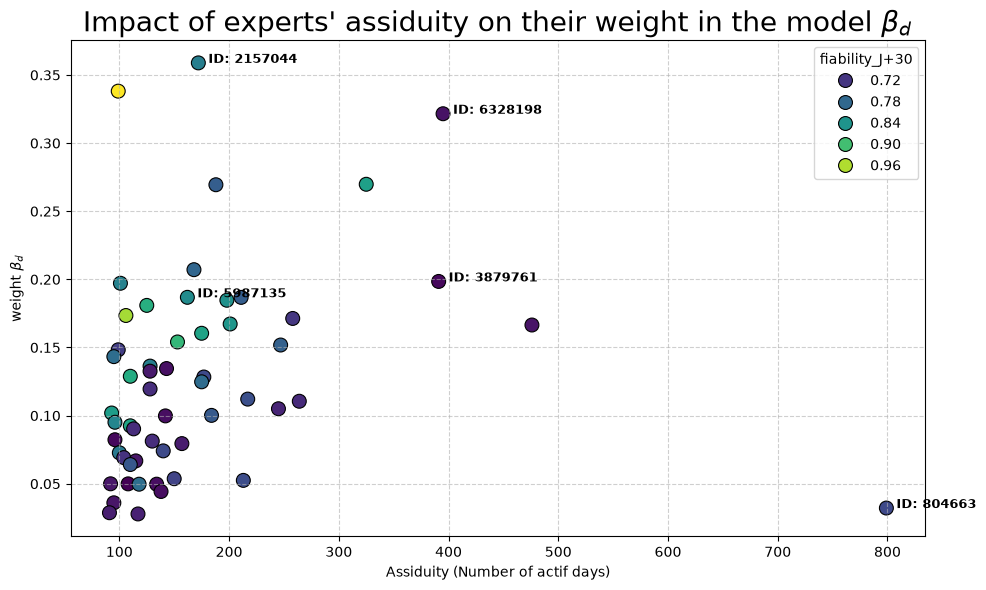

In [98]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_tsla_top_community,
                x='assiduity',
                y='coefficient',
                hue='fiability_J+30',
                palette='viridis',
                s=100,
                edgecolor='black'
)

plt.title(r"Impact of experts' assiduity on their weight in the model $\beta_d$", fontsize=20)
plt.xlabel("Assiduity (Number of actif days)", fontsize=10)
plt.ylabel(r"weight $\beta_d$", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)

for _, row in df_tsla_top_community[df_tsla_top_community['user_id'].isin([2157044, 6328198, 3879761, 5987135, 804663])].iterrows():
    plt.text(row['assiduity'], row['coefficient'], f"  ID: {int(row['user_id'])}", fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

del row

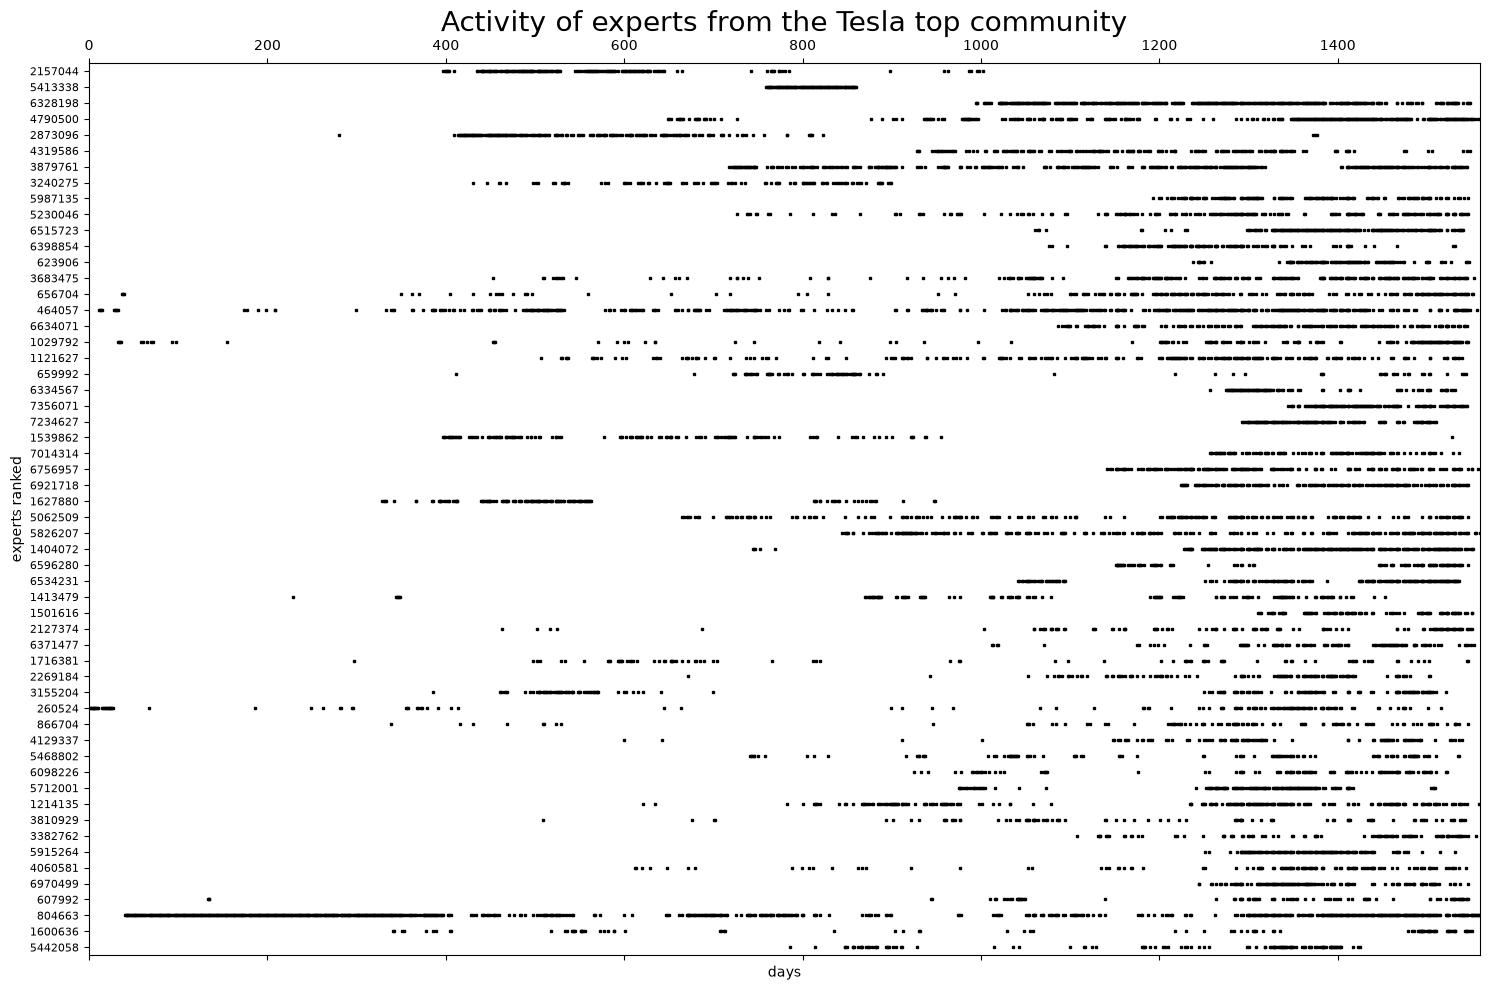

user_id,2157044,5413338,6328198,4790500,2873096,4319586,3879761,3240275,5987135,5230046,...,1214135,3810929,3382762,5915264,4060581,6970499,607992,804663,1600636,5442058
day,,,,,,,,,,,,,,,,,,,,,
2096,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
2101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
2122,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
2130,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
2131,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5838,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,-1.0,0.0,0.0,0.0,0.0,-1.000000,0.0,0.0
5839,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.800000,0.0,0.0
5840,0.0,0.0,0.0,-1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.428571,0.0,0.0


In [52]:
experts_user_id = df_tsla_top_community[experts_keeped_user_id]['user_id'].values
X_sorted = X[experts_user_id]
activity_matrix = X_sorted.T != 0

plt.figure(figsize=(15, 10))
plt.spy(activity_matrix, aspect='auto', markersize=1.5, color='black')
plt.title("Activity of experts from the Tesla top community", fontsize=20)
plt.xlabel("days", fontsize=10)
plt.ylabel("experts ranked", fontsize=10)
plt.yticks(ticks=range(len(experts_user_id)), labels=experts_user_id, fontsize=8)
plt.tight_layout()
plt.show()

del activity_matrix
X_sorted

In [78]:
df_tsla_day_top_community = df_tsla_top_messages.groupby('day')['fiability_J+30'].mean().sort_index().to_frame(name='fiability_J+30')
df_tsla_day90_top_community_mean = df_tsla_day_top_community.rolling(window=90).mean()

In [ ]:
df_tsla_day90_top_community_mean

,fiability_J+30
day,
2096,NaN
2101,NaN
2122,NaN
2130,NaN
2131,NaN
...,...
5838,0.847460
5839,0.848621
5840,0.847947


In [84]:

def temporal_activity_analysis(target_user):
    # Calcul du nombre total d'experts actifs par jour
    global_activity = (X != 0).sum(axis=1)

    # Identification des jours d'activité de l'expert à analyser
    user_activity = (X[target_user] != 0).astype(int)


    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(16, 8), sharex=True)

    ax1.plot(global_activity.values, color='b', linewidth=0.8, alpha=0.8)
    ax1.set_title("Global activity of Tesla top community (Number of actif experts by day)", fontsize=20)
    ax1.set_ylabel("Number of actif experts", fontsize=10)
    ax1.grid(True, linestyle='--', alpha=0.5)

    actif_days = np.where(user_activity.values == 1)[0]
    ax2.vlines(actif_days, ymin=0, ymax=1, color='r', linewidth=1, alpha=0.8)
    ax2.set_title(f"Activity of the expert n°{target_user}", fontsize=20)
    ax2.set_ylabel(f"Expert {target_user} actif", fontsize=10)
    ax2.set_xlabel("days", fontsize=10)
    ax2.set_ylim(-0.1, 1.1)
    ax2.grid(True, linestyle='--', alpha=0.5)

    ax3.plot(df_tsla_day90_top_community_mean['fiability_J+30'].values, 
         color='blue', 
         linewidth=1.5
         )
    ax3.set_title("90-Day Rolling Mean of Tesla top community fiability (J+30)", fontsize=20)
    ax3.set_xlabel("Day", fontsize=10)
    ax3.set_ylabel("Mean fiability (J+30)", fontsize=10)
    ax3.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

#804663 #3879761 #6328198 #2157044

###### User ID : 804663 (Ranking : N°54)

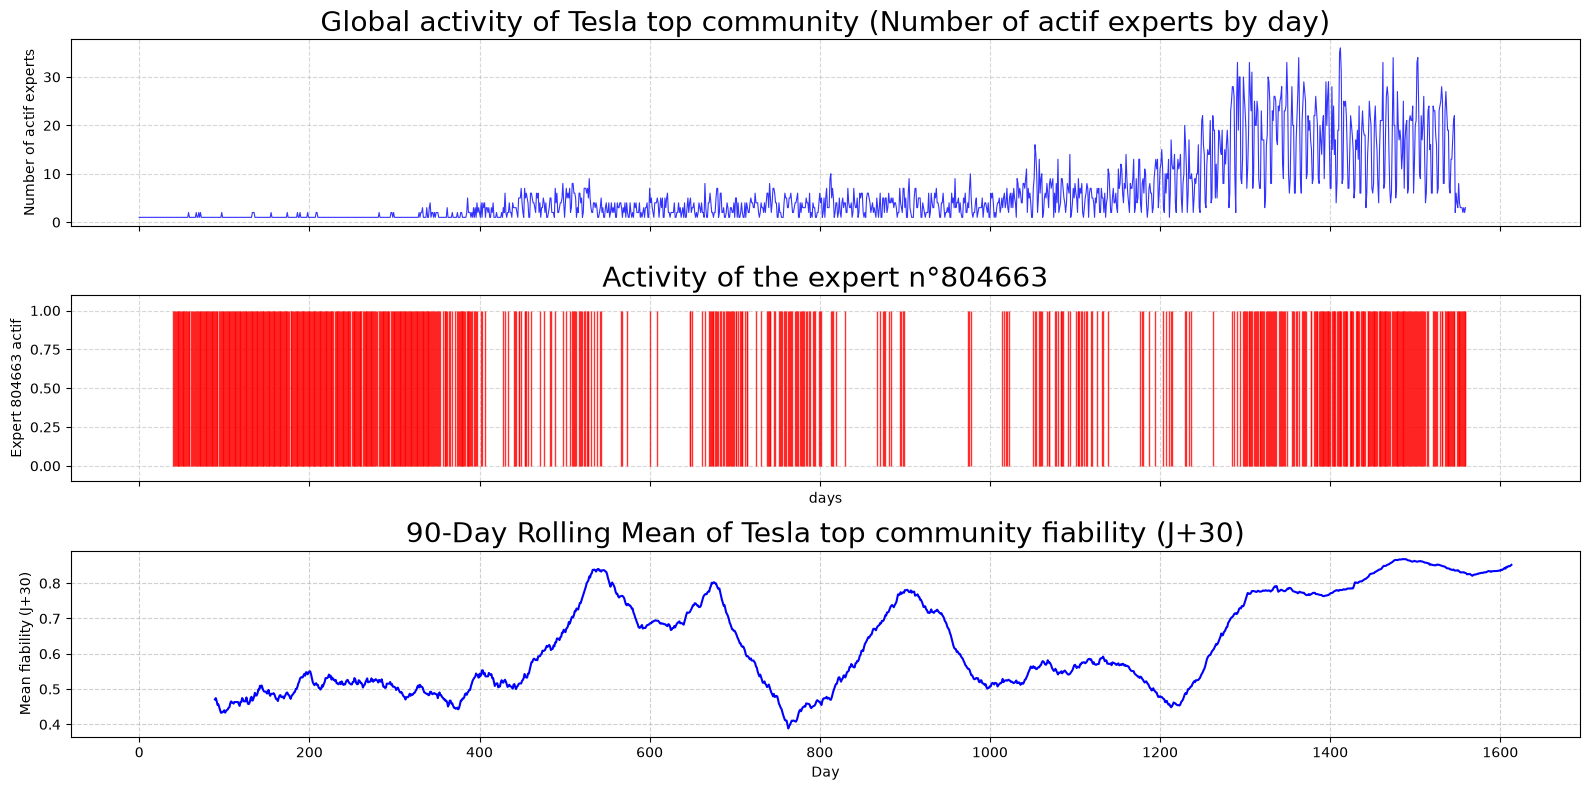

In [85]:
temporal_activity_analysis(804663)

In [90]:
target_user = 804663

df_user_804633 = df_tsla_top_messages[(df_tsla_top_messages['user_id'] == target_user) & 
                                 (df_tsla_top_messages['day'].isin(X.index[:400]))]

print(f"Nombre de messages trouvés : {len(df_user_804633)}")

del target_user
df_user_804633[['user_id', 'day', 'fiability_J+30']].describe(include='all')

Nombre de messages trouvés : 1418


,user_id,day,fiability_J+30
count,1418.0,1418.0,1418.000000
unique,1.0,338.0,NaN
top,804663.0,4159.0,NaN
freq,1418.0,25.0,NaN
mean,NaN,NaN,0.496474
std,NaN,NaN,0.500164
min,NaN,NaN,0.000000
25%,NaN,NaN,0.000000
50%,NaN,NaN,0.000000
75%,NaN,NaN,1.000000


###### User ID : 2157044 (Ranking N°1)

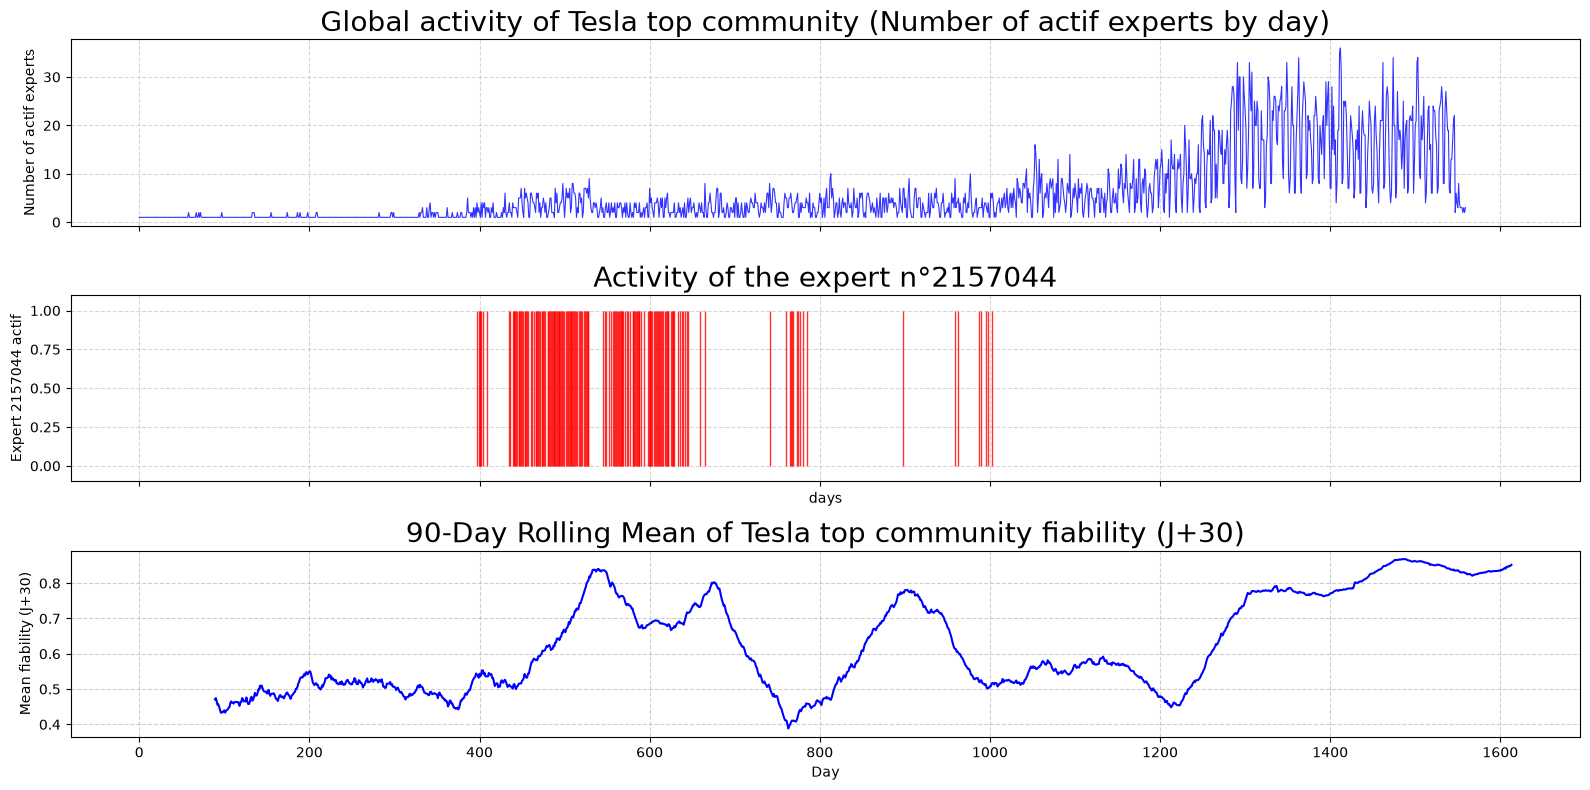

In [86]:
temporal_activity_analysis(2157044)

In [91]:
target_user = 2157044

df_user_2157044 = df_tsla_top_messages[(df_tsla_top_messages['user_id'] == target_user) & 
                                 (df_tsla_top_messages['day'].isin(X.index[390:700]))]

print(f"Nombre de messages trouvés : {len(df_user_2157044)}")

del target_user
df_user_2157044[['user_id', 'day', 'fiability_J+30']].describe(include='all')

Nombre de messages trouvés : 662


,user_id,day,fiability_J+30
count,662.0,662.0,662.000000
unique,1.0,151.0,NaN
top,2157044.0,4573.0,NaN
freq,662.0,23.0,NaN
mean,NaN,NaN,0.808157
std,NaN,NaN,0.394048
min,NaN,NaN,0.000000
25%,NaN,NaN,1.000000
50%,NaN,NaN,1.000000
75%,NaN,NaN,1.000000


###### User ID : 5987135 (Ranking N°9)

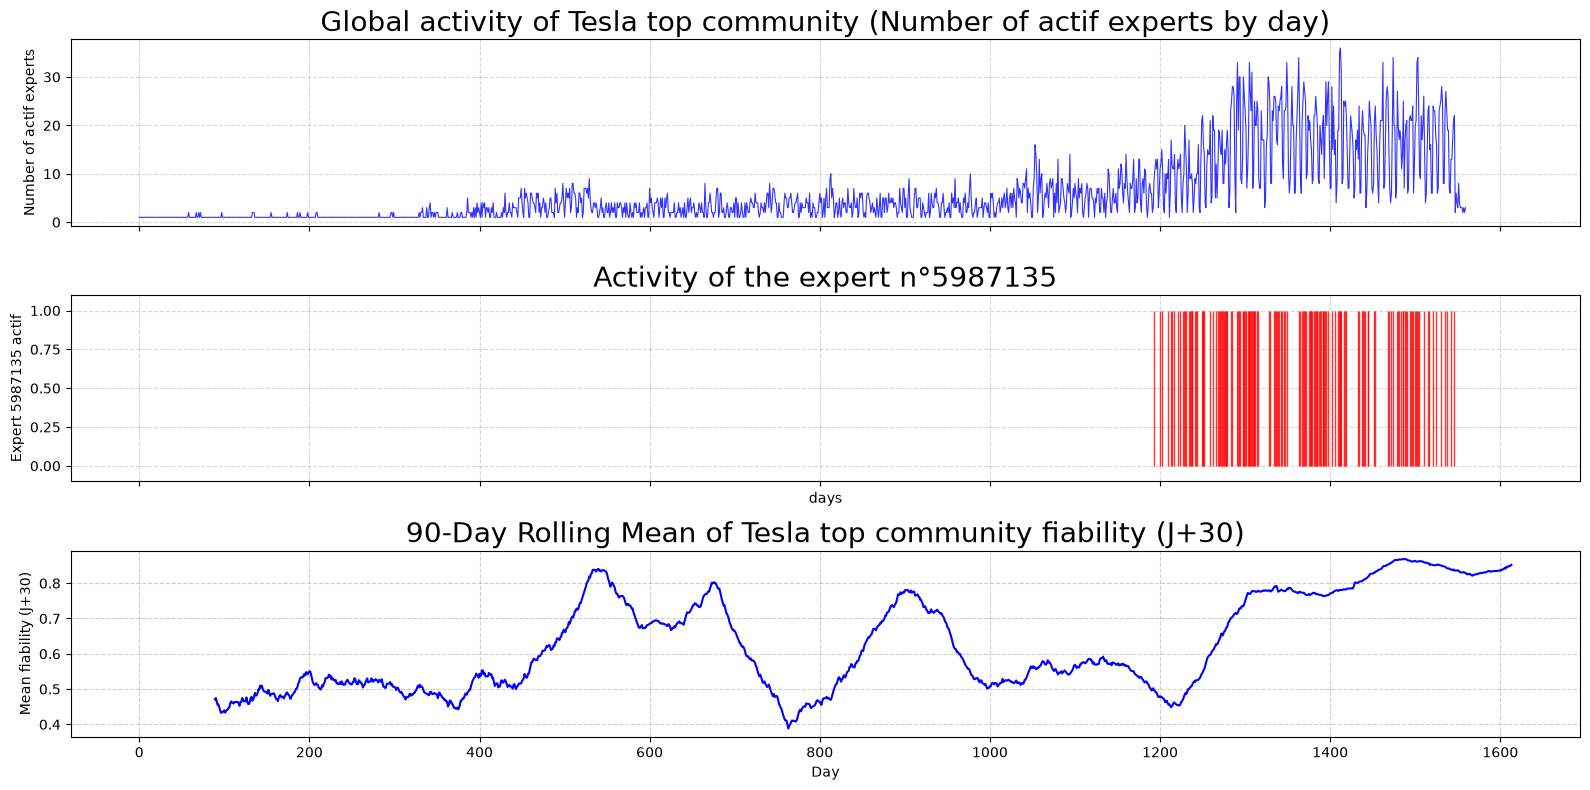

In [96]:
temporal_activity_analysis(5987135)

In [97]:
target_user = 5987135

df_user_5987135 = df_tsla_top_messages[(df_tsla_top_messages['user_id'] == target_user) & 
                                 (df_tsla_top_messages['day'].isin(X.index[1200:1600]))]

print(f"Nombre de messages trouvés : {len(df_user_5987135)}")

del target_user
df_user_5987135[['user_id', 'day', 'fiability_J+30']].describe(include='all')

Nombre de messages trouvés : 655


,user_id,day,fiability_J+30
count,655.0,655.0,655.000000
unique,1.0,161.0,NaN
top,5987135.0,5405.0,NaN
freq,655.0,18.0,NaN
mean,NaN,NaN,0.829008
std,NaN,NaN,0.376790
min,NaN,NaN,0.000000
25%,NaN,NaN,1.000000
50%,NaN,NaN,1.000000
75%,NaN,NaN,1.000000


###### User ID : 6328198 (Ranking N°3)

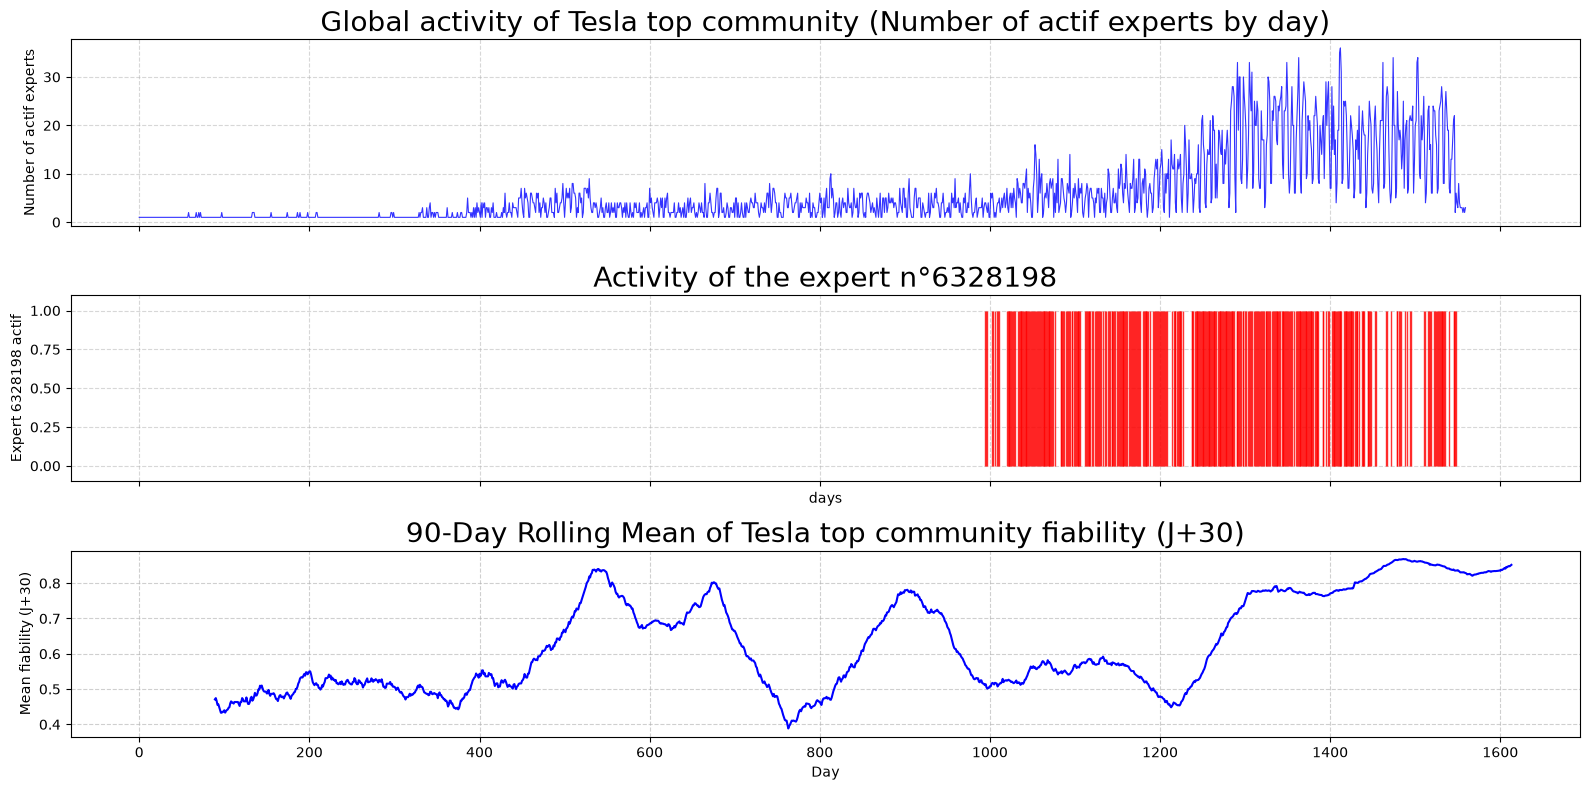

In [87]:
temporal_activity_analysis(6328198)

In [93]:
target_user = 6328198

df_user_6328198 = df_tsla_top_messages[(df_tsla_top_messages['user_id'] == target_user) & 
                                 (df_tsla_top_messages['day'].isin(X.index[990:1200]))]

print(f"Nombre de messages trouvés : {len(df_user_6328198)}")

del target_user
df_user_6328198[['user_id', 'day', 'fiability_J+30']].describe(include='all')

Nombre de messages trouvés : 1095


,user_id,day,fiability_J+30
count,1095.0,1095.0,1095.000000
unique,1.0,156.0,NaN
top,6328198.0,5239.0,NaN
freq,1095.0,34.0,NaN
mean,NaN,NaN,0.568950
std,NaN,NaN,0.495449
min,NaN,NaN,0.000000
25%,NaN,NaN,0.000000
50%,NaN,NaN,1.000000
75%,NaN,NaN,1.000000


###### User ID : 3879761 (Ranking N°7)

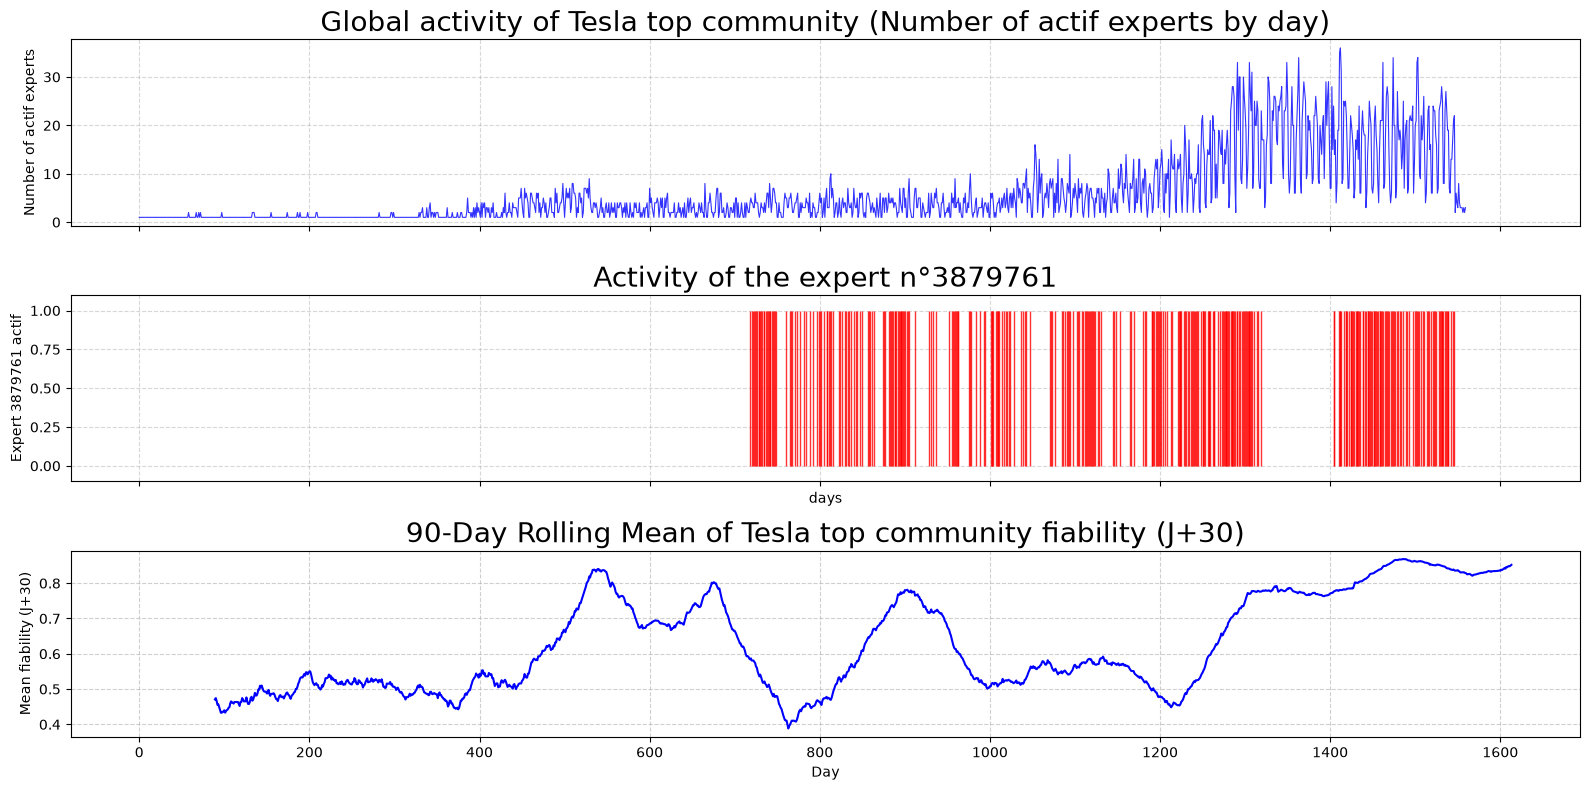

In [88]:
temporal_activity_analysis(3879761)

In [92]:
target_user = 3879761

df_user_3879761 = df_tsla_top_messages[(df_tsla_top_messages['user_id'] == target_user) & 
                                 (df_tsla_top_messages['day'].isin(X.index[700:900]))]

print(f"Nombre de messages trouvés : {len(df_user_3879761)}")

del target_user
df_user_3879761[['user_id', 'day', 'fiability_J+30']].describe(include='all')

Nombre de messages trouvés : 215


,user_id,day,fiability_J+30
count,215.0,215.0,215.000000
unique,1.0,96.0,NaN
top,3879761.0,5042.0,NaN
freq,215.0,15.0,NaN
mean,NaN,NaN,0.641860
std,NaN,NaN,0.480572
min,NaN,NaN,0.000000
25%,NaN,NaN,0.000000
50%,NaN,NaN,1.000000
75%,NaN,NaN,1.000000


### Conclusion